In [ ]:
import pandas as pd
import yfinance as yf
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, TimeSeriesSplit
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

import matplotlib.pyplot as plt

# Future Market Volatility Predictor

## Preliminaries:

We start of with the  following defintions to build our estimator for volatility:


*   Brownian Motion

    *   The collection of random variables $X(t), t ≥ 0$ is said to be a Brownian Motion with drift parameter $\mu$ and volatility parameter $\sigma$ if:
    
    1.   $X(0)$ is a given constant
    2.   $∀ y \ge 0, t \ge 0$  the random variable $X(t+y)-X(t)$ is independent of the process values up to time y and has a normal distrubution with mean μt and variance $σ^2$




*   Geometric Brownian


    *   Let $X(t),t≥0$ be a Brownian Motion process with drift parameter $\mu$ and variance $\sigma^2$, then $\\S(t) = e^{X(t)}, t\ge 0$ is a Geometric Brownian Motion process with drift parameter $\mu$ and variance $\sigma^2$


    *   If S(t) is a Geometric Brownian Motion with drift parameter $\mu$ and variance $\sigma^2$, then $\ln( \frac{S(t+y)}{S(y)})$ with mean $\mu$t and variance $\sigma^2$t









#Estimation of the volatility on a given day
To estimate the volatility on a given day we will use the opening and closing data. We start by assuming that the given stock prices follow a Geometric Brownian Motion with a drift parameter of $\mu$ and a volatility parameter of $\sigma$. From the defintion of Geometric Brownian Motion we note that $\ln( \frac{C_i}{C_{i-1}} )$ follows a normal distribution with unknown mean and variance.
To estimatee the volatility on a given date we use the following derivation:

$$
\begin{align*}
  \text{Let } X_i &= \ln( \frac{C_i}{C_{i-1}}) \\
  \text{then } X_i &= \ln( \frac{C_i*O_i}{C_{i-1} * O_i}) \\
  &= \ln( \frac{C_i}{O_i}) - \ln( \frac{C_{i-1}}{O_i}) \\
\end{align*}
$$
Using the estimator $S^2 = \frac{\sum_{i=1}^{n} (X_i - \bar{X_i})^2}{n-1}$ we get the estimated volatility on a given day.

In [ ]:
df = yf.download("AAPL", start = "2020-01-01", end = "2026-01-01")

#------------------Log returns------------------------------
df["Intraday"] = np.log(df["Close"]/df["Open"])
df["Overnight"] = np.log(df["Close"].shift(1)/df["Open"])
df["Xi"] = df["Intraday"] - df["Overnight"]

#--------------Rolling volatility (20 days)----------------
df["Roling_Vol"] = df["Xi"].rolling(window = 20).std()
df["Future_Vol_5"] = df["Roling_Vol"].shift(-5)
df["Future_Vol_10"] = df["Roling_Vol"].shift(-10)
df["Future_Vol_20"] = df["Roling_Vol"].shift(-20)

df = df.dropna()

X = df.drop(columns = ["Future_Vol_5","Future_Vol_10","Future_Vol_20"])
y1 = df["Future_Vol_5"]
y2 = df["Future_Vol_10"]
y3 = df["Future_Vol_20"]

df
#-------------------Preperation--------------------

split = int(len(X) * 0.8)

un_Xtr = X.iloc[:split]
un_Xte = X.iloc[split:]

y1tr = y1.iloc[:split]
y1te = y1.iloc[split:]
y2tr = y2.iloc[:split]
y2te = y2.iloc[split:]
y3tr = y3.iloc[:split]
y3te = y3.iloc[split:]

scaler = StandardScaler().fit(un_Xtr)
Xtr = scaler.transform(un_Xtr)
Xte = scaler.transform(un_Xte)

/tmp/ipykernel_824/740649147.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("AAPL", start = "2020-01-01", end = "2026-01-01")
[*********************100%***********************]  1 of 1 completed


For the split into training and test data because we are working with Time Series data the data cannot be randomly split which is why we use this method to splt the data into the training and test set.

In [ ]:
#----------------Feature Selection & Extraction-------------
pca = PCA(n_components=4).fit(Xtr)
Xtr_pca = pca.transform(Xtr)
Xte_pca = pca.transform(Xte)

#Why Ridge Regression might perform better than the other Regression models tested when none of the features are removed
##Linear Regression
Ridge Regression performs better htna linear regression when there is multicolinearity present in the data. With the data that we have some of the fields are calculated based on other fields which introduces some linear dependence in the data. This means that there is more multicolinearity and Ridge Regression perorms better.
##Decision Tree:




In [ ]:

#-----------------Model Selection---------------------------
#------Models we are comparing------
models = {"Linear" : [make_pipeline(PolynomialFeatures(), LinearRegression()), { "polynomialfeatures__degree" : [1,2,5,7,10]}]
, "Ridge" : [Ridge(), {"alpha" : [0.001, 0.01, 0.1, 1, 10, 100, 1000]}]
, "Tree" : [DecisionTreeRegressor(), {"max_depth" : [None, 3, 6,12,24]}]
, "Forest" : [RandomForestRegressor(), {
    'max_depth': [None, 10, 20, 30],
    'max_features': ['sqrt', 'log2', 0.5]}]
, "SVR" : [SVR(), [
    {
        'kernel': ['rbf'],
        'C': [0.1, 1, 10, 100],
        'gamma': ['scale', 'auto', 0.01, 0.1, 1],
        'epsilon': [0.01, 0.1, 0.5, 1.0]
    },
    {
        'kernel': ['linear'],
        'C': [0.1, 1, 10, 100],
        'epsilon': [0.01, 0.1, 0.5, 1.0]
    }
]]}

results = {}
for model in models:
  grid = GridSearchCV(models[model][0], cv = TimeSeriesSplit(n_splits=5, gap = 5), param_grid = models[model][1], scoring = "neg_mean_squared_error", n_jobs=-1).fit(Xtr,y1tr)
  print(grid.best_params_)

  results[model] = [grid.best_score_*-1, grid.best_params_]

print(results)


{'polynomialfeatures__degree': 1}
{'alpha': 0.1}
{'max_depth': 3}
{'max_depth': None, 'max_features': 0.5}
{'C': 0.1, 'epsilon': 0.01, 'kernel': 'linear'}
{'Linear': [np.float64(6.419579392474589e-06), {'polynomialfeatures__degree': 1}], 'Ridge': [np.float64(6.321968543490337e-06), {'alpha': 0.1}], 'Tree': [np.float64(1.1803344673584389e-05), {'max_depth': 3}], 'Forest': [np.float64(2.770711857538496e-05), {'max_depth': None, 'max_features': 0.5}], 'SVR': [np.float64(1.3809697492751704e-05), {'C': 0.1, 'epsilon': 0.01, 'kernel': 'linear'}]}


In [ ]:
print(results)
best_model = ""
min_mse = np.inf
i = 0

for res in results:
  if results[res][0] < min_mse:
    min_mse = results[res][0]
    best_model = res

print(best_model, min_mse)

{'Linear': [np.float64(6.419579392474589e-06), {'polynomialfeatures__degree': 1}], 'Ridge': [np.float64(6.321968543490337e-06), {'alpha': 0.1}], 'Tree': [np.float64(1.1803344673584389e-05), {'max_depth': 3}], 'Forest': [np.float64(2.770711857538496e-05), {'max_depth': None, 'max_features': 0.5}], 'SVR': [np.float64(1.3809697492751704e-05), {'C': 0.1, 'epsilon': 0.01, 'kernel': 'linear'}]}
Ridge 6.321968543490337e-06


Using the original data with none of the deatures removed we see that the Ridge Regression model has the lowest Mean Squared error and therfore when none of the data points are remove this is the model that we would select.


#Discusion of the prediction and tests:

From our graph comparing the predicteed value and the actually volatility we see that our selected model (Ridge ) follows the actuall volatilty prices quite well. The dips and uptakes in volatilty are followed quite closely by the model.

From the test scores we see that both Linear regression and Ridge Regression perform similarly on unseen data and they have the highest test scores. SVR, Decision tree and Random Forests perform significantly worse Linear and Ridge Regression.

Linear and Ridge regression are quite similar models which explains why they perform similarly. Decision Tree Regression performs worse because it predicts based on the data which falls in a certain interval and all data points where the data falls in the same interval will have the same predicted value.

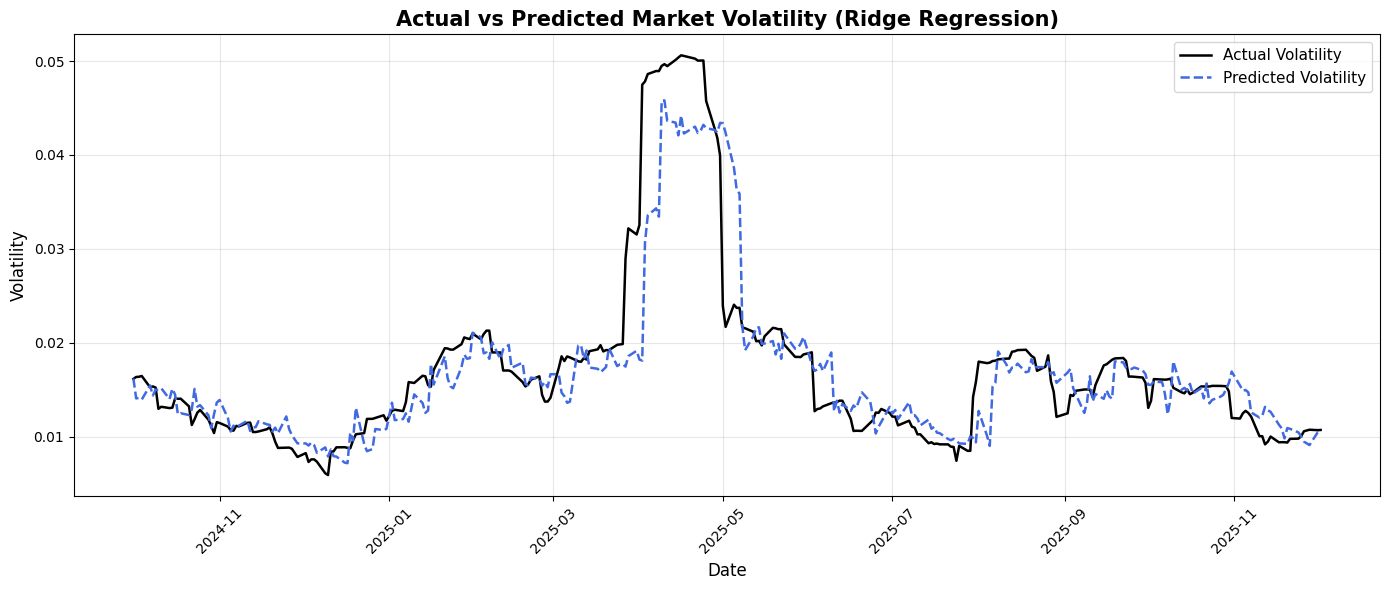

In [ ]:
selected_model = Ridge(alpha=0.1).fit(Xtr, y1tr)
y_pred = selected_model.predict(Xte)

plt.figure(figsize=(14, 6))

plt.plot(y1te.index, y1te,
         label="Actual Volatility",
         color="black",
         linewidth=1.8)

plt.plot(y1te.index, y_pred,
         label="Predicted Volatility",
         color="royalblue",
         linewidth=1.8,
         linestyle="--")

plt.title("Actual vs Predicted Market Volatility (Ridge Regression)",
          fontsize=15, fontweight="bold")

plt.xlabel("Date", fontsize=12)
plt.ylabel("Volatility", fontsize=12)

plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
#Test accuracies for each regression model
print(results)
scLin = LinearRegression().fit(Xtr,y1tr).score(Xte,y1te)
scRidge = Ridge(0.1).fit(Xtr,y1tr).score(Xte,y1te)
scTree = DecisionTreeRegressor(max_depth = 3).fit(Xtr,y1tr).score(Xte,y1te)
scFor = RandomForestRegressor(max_features = 0.5).fit(Xtr,y1tr).score(Xte,y1te)
scSVR = SVR(kernel = "linear", C = 0.1, epsilon = 0.01).fit(Xtr,y1tr).score(Xte,y1te)

data = {
    "Model": ["Linear", "Ridge", "Decision Tree", "Random Forest", "SVR"],
    "Score": [scLin, scRidge, scTree, scFor, scSVR]
}

output_df = pd.DataFrame(data)
output_df

{'Linear': [np.float64(6.419579392474589e-06), {'polynomialfeatures__degree': 1}], 'Ridge': [np.float64(6.321968543490337e-06), {'alpha': 0.1}], 'Tree': [np.float64(1.1803344673584389e-05), {'max_depth': 3}], 'Forest': [np.float64(2.770711857538496e-05), {'max_depth': None, 'max_features': 0.5}], 'SVR': [np.float64(1.3809697492751704e-05), {'C': 0.1, 'epsilon': 0.01, 'kernel': 'linear'}]}


,Model,Score
0,Linear,0.788963
1,Ridge,0.788916
2,Decision Tree,0.631917
3,Random Forest,0.550101
4,SVR,0.630614
